# POD-Galerkin from precomputed FOM data

This notebook performs the POD-Galerkin offline/online workflow using
**precomputed FOM snapshots** generated by `generate_FOM_dataset.ipynb`.

The FOM is **not solved here**. The saved training snapshots are used to
construct the POD basis, while the saved test snapshots are used for the
final FOM-vs-ROM validation.


In [2]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ColabNotebooks/MOR-Project"
%cd $PROJECT_DIR

!pip install -r requirements.txt


Mounted at /content/drive
/content/drive/MyDrive/ColabNotebooks/MOR-Project
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.7/139.7 MB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 7.7 MB/s eta 0:00:00


In [3]:
import os
import time

import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt

from pypolydim import polydim, gedim
from pypolydim.export_vtk_utilities import ExportVTKUtilities

import sys
sys.path.insert(1, "../")
import other_utilities as other_ut


## 1. FEM model setup

The following cells reuse the FEM discretization from the original POD-Galerkin notebook. The difference is that no FOM solves are performed here.

In [4]:
geometry_utilities_config = gedim.GeometryUtilitiesConfig()

geometry_utilities_config.tolerance1_d = 1.0e-6
geometry_utilities_config.tolerance2_d = 1.0e-12

geometry_utilities = gedim.GeometryUtilities(
    geometry_utilities_config
)

mesh_utilities = gedim.MeshUtilities()

vtk_utilities = ExportVTKUtilities()

In [5]:
pde_domain = polydim.pde_tools.mesh.pde_mesh_utilities.PDE_Domain_2D()

pde_domain.vertices = np.array([
    [0.0, 1.0, 1.0, 0.0],
    [0.0, 0.0, 1.0, 1.0],
    [0.0, 0.0, 0.0, 0.0]
])

pde_domain.shape_type = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .PDE_Domain_2D.Domain_Shape_Types.parallelogram
)

pde_domain.area = 1.0

In [6]:
mesh_type = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .MeshGenerator_Types_2D.triangular
)

method_type = (
    polydim.pde_tools.local_space_pcc_2_d.MethodTypes.fem_pcc
)

mesh_size = 0.001

In [7]:
mesh_data = gedim.MeshMatrices()

mesh = gedim.MeshMatricesDAO(mesh_data)

polydim.pde_tools.mesh.pde_mesh_utilities.create_mesh_2_d(
    geometry_utilities,
    mesh_utilities,
    mesh_type,
    pde_domain,
    mesh_size,
    mesh
)

mesh_geometric_data = (
    polydim.pde_tools.mesh.pde_mesh_utilities
    .compute_mesh_2_d_geometry_data(
        geometry_utilities,
        mesh_utilities,
        mesh
    )
)

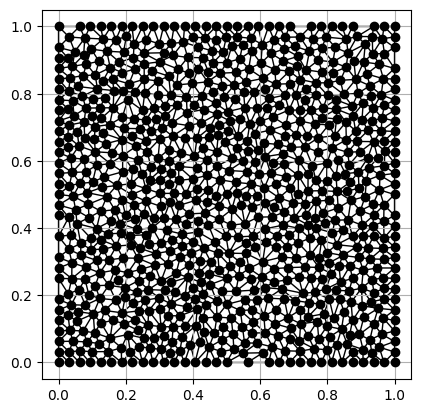

In [8]:
other_ut.plot_mesh(mesh)

In [9]:
# Defining border info.
info_internal = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_internal.marker = 0

info_dirichlet = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.strong)
info_dirichlet.marker = 1

info_neumann_none = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none)
info_neumann_none.marker = 0

# p=0 on all borders.
pressure_boundary_info = {
    0: info_internal,
    1: info_dirichlet,
    2: info_neumann_none,
    3: info_neumann_none,
    4: info_neumann_none,
    5: info_neumann_none,
    6: info_neumann_none,
    7: info_neumann_none,
    8: info_neumann_none
}

# u=v=0 on all borders.
speed_boundary_info = {
    0: info_internal,
    1: info_dirichlet,
    2: info_dirichlet,
    3: info_dirichlet,
    4: info_dirichlet,
    5: info_dirichlet,
    6: info_dirichlet,
    7: info_dirichlet,
    8: info_dirichlet
}

In [10]:
# ============================================================
# Mesh connectivity and reference elements
# ============================================================

mesh_connectivity_data = (
    polydim.pde_tools.mesh
    .MeshMatricesDAO_mesh_connectivity_data(mesh)
)

pressure_reference_element_data = (
    polydim.pde_tools.local_space_pcc_2_d
    .create_reference_element(method_type, 1)
)

speed_reference_element_data = (
    polydim.pde_tools.local_space_pcc_2_d
    .create_reference_element(method_type, 2)
)

dof_manager = polydim.pde_tools.do_fs.DOFsManager()


# ============================================================
# Pressure DOFs
# ============================================================

pressure_mesh_dofs_info = (
    polydim.pde_tools.local_space_pcc_2_d
    .set_mesh_do_fs_info(
        pressure_reference_element_data,
        mesh,
        pressure_boundary_info
    )
)

pressure_dofs_data = (
    dof_manager.create_do_fs_2_d(
        pressure_mesh_dofs_info,
        mesh_connectivity_data
    )
)


# ============================================================
# Velocity DOFs
# ============================================================

speed_mesh_dofs_info = (
    polydim.pde_tools.local_space_pcc_2_d
    .set_mesh_do_fs_info(
        speed_reference_element_data,
        mesh,
        speed_boundary_info
    )
)

speed_dofs_data = (
    dof_manager.create_do_fs_2_d(
        speed_mesh_dofs_info,
        mesh_connectivity_data
    )
)

In [11]:
pressure_n_dofs = pressure_dofs_data.number_do_fs
pressure_n_strongs = pressure_dofs_data.number_strongs

speed_n_dofs = speed_dofs_data.number_do_fs
speed_n_strongs = speed_dofs_data.number_strongs

tot_dofs = 2 * speed_n_dofs + pressure_n_dofs
tot_strongs = 2 * speed_n_strongs + pressure_n_strongs

print("Pressure DOFs :", pressure_n_dofs)
print("Velocity DOFs :", 2 * speed_n_dofs)
print("Total DOFs    :", tot_dofs)

print("Pressure strong DOFs :", pressure_n_strongs)
print("Velocity strong DOFs :", 2 * speed_n_strongs)
print("Total strong DOFs    :", tot_strongs)

Pressure DOFs : 829
Velocity DOFs : 5932
Total DOFs    : 6761
Pressure strong DOFs : 1
Velocity strong DOFs : 468
Total strong DOFs    : 469


In [12]:
def unit_term(x, y, z):
    return 1.0

def b_x_term(x, y, z):
    return np.array([1.0, 0.0, 0.0])


def b_y_term(x, y, z):
    return np.array([0.0, 1.0, 0.0])

In [13]:
def make_f_functions(mu1):

    pi = np.pi

    def f_x_function(x, y, z):
        return (
            -(mu1**3 * pi**2 * np.cos(mu1**2 * pi * x)
              - mu1**2 * pi**2)
            * np.sin(mu1 * pi * y)
            * np.cos(mu1 * pi * y)
            + mu1 * pi
            * np.cos(mu1 * pi * x)
            * np.cos(mu1 * pi * y)
        )

    def f_y_function(x, y, z):
        return (
            -(-mu1**3 * pi**2 * np.cos(mu1**2 * pi * y)
              + mu1**2 * pi**2)
            * np.sin(mu1 * pi * x)
            * np.cos(mu1 * pi * x)
            - mu1 * pi
            * np.sin(mu1 * pi * x)
            * np.sin(mu1 * pi * y)
        )

    return f_x_function, f_y_function

In [14]:
def assemble_f(mu1):

    f_x_function, f_y_function = make_f_functions(mu1)

    f_x = (
        polydim.pde_tools.assembler_utilities.pcc_2_d
        .assemble_source_term(
            geometry_utilities,
            mesh,
            mesh_geometric_data,
            speed_dofs_data,
            speed_reference_element_data,
            speed_reference_element_data,
            f_x_function
        )
    )

    f_y = (
        polydim.pde_tools.assembler_utilities.pcc_2_d
        .assemble_source_term(
            geometry_utilities,
            mesh,
            mesh_geometric_data,
            speed_dofs_data,
            speed_reference_element_data,
            speed_reference_element_data,
            f_y_function
        )
    )

    return np.concatenate([
        f_x,
        f_y,
        np.zeros(pressure_n_dofs)
    ])

In [15]:
F_test = assemble_f(mu1=2.0)

print("F shape:", F_test.shape)
print("Expected:", (tot_dofs,))
print("||F|| =", np.linalg.norm(F_test))

F shape: (6761,)
Expected: (6761,)
||F|| = 0.7217278387973323


In [16]:
# ============================================================
# FEM diffusion operator
# ============================================================

A_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_diffusion_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        speed_dofs_data,
        speed_reference_element_data,
        speed_reference_element_data,
        unit_term
    )
)

J_A_x = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [0, 0]
)

J_A_y = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [speed_n_dofs, speed_n_dofs]
)

J_A = J_A_x + J_A_y


# ============================================================
# Velocity-pressure coupling
# ============================================================

B_x_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_advection_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        pressure_dofs_data,
        speed_reference_element_data,
        pressure_reference_element_data,
        b_x_term
    )
)

B_y_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_advection_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_dofs_data,
        pressure_dofs_data,
        speed_reference_element_data,
        pressure_reference_element_data,
        b_y_term
    )
)

J_B_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0]
)

J_B_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs]
)

J_BT_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0],
    True
)

J_BT_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs],
    True
)

J_B = J_B_x + J_B_y + J_BT_x + J_BT_y

In [17]:
# ============================================================
# Robust FEM matrix checks
# ============================================================

expected_global_shape = (tot_dofs, tot_dofs)

matrices = {
    "J_A": J_A,
    "J_B_x": J_B_x,
    "J_B_y": J_B_y,
    "J_B": J_B,
}

print(f"Expected global matrix shape: {expected_global_shape}")

all_passed = True

for name, matrix in matrices.items():

    passed = matrix.shape == expected_global_shape
    all_passed &= passed

    print(
        f"{name:6s}: actual = {matrix.shape}, "
        f"expected = {expected_global_shape} -> "
        f"{'PASS' if passed else 'FAIL'}"
    )

print(
    "\nFEM matrix dimension check:",
    "PASSED" if all_passed else "FAILED"
)

if not all_passed:
    raise ValueError("FEM matrix dimension check failed.")

# ============================================================
# Local operator shape checks
# ============================================================

expected_A_shape = (speed_n_dofs, speed_n_dofs)
expected_B_shape = (pressure_n_dofs, speed_n_dofs)

local_matrices = {
    "A_operator": (
        A_operator.operator_dofs,
        expected_A_shape
    ),
    "B_x_operator": (
        B_x_operator.operator_dofs,
        expected_B_shape
    ),
    "B_y_operator": (
        B_y_operator.operator_dofs,
        expected_B_shape
    ),
}

all_passed_local = True

for name, (data, expected_shape) in local_matrices.items():

    actual_shape = tuple(data.size)

    passed = actual_shape == expected_shape
    all_passed_local &= passed

    print(
        f"{name:12s}: actual = {actual_shape}, "
        f"expected = {expected_shape} -> "
        f"{'PASS' if passed else 'FAIL'}"
    )

print(
    "\nLocal operator dimension check:",
    "PASSED" if all_passed_local else "FAILED"
)

if not all_passed_local:
    raise ValueError("Local FEM operator dimension check failed.")

Expected global matrix shape: (6761, 6761)
J_A   : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B_x : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B_y : actual = (6761, 6761), expected = (6761, 6761) -> PASS
J_B   : actual = (6761, 6761), expected = (6761, 6761) -> PASS

FEM matrix dimension check: PASSED
A_operator  : actual = (2966, 2966), expected = (2966, 2966) -> PASS
B_x_operator: actual = (829, 2966), expected = (829, 2966) -> PASS
B_y_operator: actual = (829, 2966), expected = (829, 2966) -> PASS

Local operator dimension check: PASSED


In [18]:
# ============================================================
# Strong boundary-value objects
# ============================================================

def zero_strong(marker, x, y, z):
    return 0.0


u_x_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_mesh_dofs_info,
        speed_dofs_data,
        speed_reference_element_data,
        zero_strong
    )
)

u_y_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        speed_mesh_dofs_info,
        speed_dofs_data,
        speed_reference_element_data,
        zero_strong
    )
)

p_strong = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_strong_solution(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        pressure_mesh_dofs_info,
        pressure_dofs_data,
        pressure_reference_element_data,
        zero_strong
    )
)

print("Strong boundary-value objects created.")

Strong boundary-value objects created.


## 2. Load the precomputed FOM dataset

The dataset notebook stores

- `train_parameters.npy`
- `train_snapshots.npy`
- `train_metadata.npy`
- `test_parameters.npy`
- `test_snapshots.npy`
- `test_metadata.npy`

in `data/fom/`.


In [19]:
DATA_DIR = os.path.join(PROJECT_DIR, "data", "fom")

train_parameters = np.load(
    os.path.join(DATA_DIR, "train_parameters.npy")
)
train_snapshots = np.load(
    os.path.join(DATA_DIR, "train_snapshots.npy")
)
train_metadata = np.load(
    os.path.join(DATA_DIR, "train_metadata.npy"),
    allow_pickle=True
)

test_parameters = np.load(
    os.path.join(DATA_DIR, "test_parameters.npy")
)
test_snapshots = np.load(
    os.path.join(DATA_DIR, "test_snapshots.npy")
)
test_metadata = np.load(
    os.path.join(DATA_DIR, "test_metadata.npy"),
    allow_pickle=True
)

print("Training parameters :", train_parameters.shape)
print("Training snapshots  :", train_snapshots.shape)
print("Test parameters     :", test_parameters.shape)
print("Test snapshots      :", test_snapshots.shape)


Training parameters : (100, 2)
Training snapshots  : (100, 6761)
Test parameters     : (50, 2)
Test snapshots      : (50, 6761)


In [20]:
# Verify that the stored snapshots match the current FEM discretization.

assert train_snapshots.shape[1] == tot_dofs, (
    f"Training snapshots have {train_snapshots.shape[1]} DOFs, "
    f"but current FEM discretization has {tot_dofs}."
)

assert test_snapshots.shape[1] == tot_dofs, (
    f"Test snapshots have {test_snapshots.shape[1]} DOFs, "
    f"but current FEM discretization has {tot_dofs}."
)

assert train_parameters.shape[1] == 2
assert test_parameters.shape[1] == 2

print("Dataset/FEM dimension checks: PASSED")


Dataset/FEM dimension checks: PASSED


## 3. Build POD inner products and divergence operator

These are the same matrices used by the original implementation. No snapshots are generated here.

In [21]:
# Velocity inner product:
# X_u = diag(A, A)

X_ux = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [2 * speed_n_dofs, 2 * speed_n_dofs],
    [0, 0]
)

X_uy = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [2 * speed_n_dofs, 2 * speed_n_dofs],
    [speed_n_dofs, speed_n_dofs]
)

inner_product_u = X_ux + X_uy

# Divergence operator B_div: velocity -> pressure
B_1 = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [pressure_n_dofs, 2 * speed_n_dofs],
    [0, 0]
)

B_2 = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [pressure_n_dofs, 2 * speed_n_dofs],
    [0, speed_n_dofs]
)

B_div = B_1 + B_2

assert inner_product_u.shape == (
    2 * speed_n_dofs,
    2 * speed_n_dofs
)

assert B_div.shape == (
    pressure_n_dofs,
    2 * speed_n_dofs
)

print("inner_product_u:", inner_product_u.shape)
print("B_div          :", B_div.shape)


inner_product_u: (5932, 5932)
B_div          : (829, 5932)


## 4. Split the saved snapshots and compute supremizers

For POD-Galerkin, the velocity and pressure snapshots are taken directly from the saved FOM solutions. Supremizer snapshots are derived from the saved pressure snapshots; this does not require another FOM solve.

In [22]:
# Snapshot layout from the FOM solver:
# U = [u_x, u_y, p]

snapshot_matrix_u = train_snapshots[:, :2 * speed_n_dofs]
snapshot_matrix_p = train_snapshots[:, 2 * speed_n_dofs:]

snapshot_matrix_s = np.zeros_like(snapshot_matrix_u)

for i, p_snapshot in enumerate(snapshot_matrix_p):
    snapshot_matrix_s[i] = scipy.sparse.linalg.spsolve(
        inner_product_u,
        B_div.T @ p_snapshot
    )

print("Velocity snapshots   :", snapshot_matrix_u.shape)
print("Supremizer snapshots :", snapshot_matrix_s.shape)
print("Pressure snapshots   :", snapshot_matrix_p.shape)


Velocity snapshots   : (100, 5932)
Supremizer snapshots : (100, 5932)
Pressure snapshots   : (100, 829)


## 5. POD covariance matrices

In [23]:
C_u = (
    snapshot_matrix_u
    @ inner_product_u
    @ snapshot_matrix_u.T
)

C_s = (
    snapshot_matrix_s
    @ inner_product_u
    @ snapshot_matrix_s.T
)

C_p = (
    snapshot_matrix_p
    @ snapshot_matrix_p.T
)

n_train = len(train_parameters)

for name, C in {
    "C_u": C_u,
    "C_s": C_s,
    "C_p": C_p,
}.items():
    assert C.shape == (n_train, n_train)
    print(f"{name}: {C.shape}")


C_u: (100, 100)
C_s: (100, 100)
C_p: (100, 100)


## 6. POD eigenvalue / energy analysis

In [24]:
def pod_eigen_analysis(C, energy_tolerance=1e-7, N_max=20):
    # C is symmetric
    eigenvalues, eigenvectors = np.linalg.eigh(C)

    # Largest eigenvalues first
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Remove tiny negative values from roundoff
    eigenvalues = np.clip(eigenvalues, 0.0, None)

    total_energy = eigenvalues.sum()

    if total_energy <= 0.0:
        raise ValueError("Covariance matrix contains no positive energy.")

    retained_energy = np.cumsum(eigenvalues) / total_energy

    # Retain at least (1 - energy_tolerance) of the POD energy.
    required = np.searchsorted(
        retained_energy,
        1.0 - energy_tolerance
    ) + 1

    N = min(required, N_max)

    return eigenvalues, eigenvectors, retained_energy, N


POD_TOL = 1e-7
N_MAX = 20

eig_u, vec_u, energy_u, N_u = pod_eigen_analysis(
    C_u, POD_TOL, N_MAX
)

eig_s, vec_s, energy_s, N_s = pod_eigen_analysis(
    C_s, POD_TOL, N_MAX
)

eig_p, vec_p, energy_p, N_p = pod_eigen_analysis(
    C_p, POD_TOL, N_MAX
)

print("Velocity modes   :", N_u)
print("Supremizer modes :", N_s)
print("Pressure modes   :", N_p)


Velocity modes   : 20
Supremizer modes : 20
Pressure modes   : 20


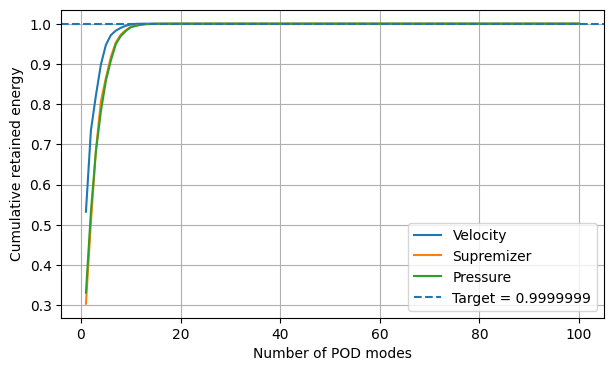

In [37]:
plt.figure(figsize=(7, 4))

plt.plot(
    np.arange(1, len(energy_u) + 1),
    energy_u,
    label="Velocity"
)

plt.plot(
    np.arange(1, len(energy_s) + 1),
    energy_s,
    label="Supremizer"
)

plt.plot(
    np.arange(1, len(energy_p) + 1),
    energy_p,
    label="Pressure"
)

target = 1.0 - POD_TOL
plt.axhline(
    target,
    linestyle="--",
    label=f"Target = {target:.7f}"
)

plt.xlabel("Number of POD modes")
plt.ylabel("Cumulative retained energy")

plt.grid(True)
plt.legend()
plt.show()


## 7. Construct the POD basis

In [26]:
def build_pod_basis(
    snapshots,
    eigenvectors,
    n_modes,
    inner_product=None
):
    basis = np.zeros(
        (snapshots.shape[1], n_modes)
    )

    for n in range(n_modes):
        mode = snapshots.T @ eigenvectors[:, n]

        if inner_product is None:
            norm = np.linalg.norm(mode)
        else:
            norm = np.sqrt(
                mode @ (inner_product @ mode)
            )

        if norm < 1e-14:
            raise ValueError(
                f"Mode {n} has a near-zero norm."
            )

        basis[:, n] = mode / norm

    return basis


V_u = build_pod_basis(
    snapshot_matrix_u,
    vec_u,
    N_u,
    inner_product=inner_product_u
)

V_s = build_pod_basis(
    snapshot_matrix_s,
    vec_s,
    N_s,
    inner_product=inner_product_u
)

V_p = build_pod_basis(
    snapshot_matrix_p,
    vec_p,
    N_p
)

N_tot = N_u + N_s + N_p

B = np.zeros(
    (tot_dofs, N_tot)
)

B[
    :2 * speed_n_dofs,
    :N_u
] = V_u

B[
    :2 * speed_n_dofs,
    N_u:N_u + N_s
] = V_s

B[
    2 * speed_n_dofs:,
    N_u + N_s:
] = V_p

print("V_u:", V_u.shape)
print("V_s:", V_s.shape)
print("V_p:", V_p.shape)
print("B  :", B.shape)

assert B.shape == (tot_dofs, N_tot)


V_u: (5932, 20)
V_s: (5932, 20)
V_p: (829, 20)
B  : (6761, 60)


## 8. Galerkin projection

In [27]:
A_r = B.T @ (J_A @ B)
B_r = B.T @ (J_B @ B)

assert A_r.shape == (N_tot, N_tot)
assert B_r.shape == (N_tot, N_tot)

print("A_r:", A_r.shape)
print("B_r:", B_r.shape)


A_r: (60, 60)
B_r: (60, 60)


## 9. Online POD-Galerkin solver

The online solver is unchanged in its basic method: the saved FOM dataset supplies the reference solutions, while each ROM prediction still assembles the nonlinear convection operator at the current reduced state.

In [28]:
def solve_ROM(
    mu0,
    mu1,
    B,
    A_r,
    B_r,
    newton_tol=1.0e-6,
    max_iterations=20,
    verbose=True
):
    # Parameter-dependent forcing
    f_full = assemble_f(mu1)
    f_r = B.T @ f_full

    # Parameter-dependent reduced linear operator
    J_lin_r = mu0 * A_r - B_r

    # Initial reduced solution
    a = np.zeros(B.shape[1])

    residual_norm = 1.0
    solution_norm = 1.0
    history = []

    for iteration in range(1, max_iterations + 1):

        if residual_norm <= newton_tol * solution_norm:
            break

        # Reconstruct current full FE approximation
        U_full = B @ a

        u_x = U_full[:speed_n_dofs]
        u_y = U_full[speed_n_dofs:2 * speed_n_dofs]

        # Assemble nonlinear convection operator
        c_operator = (
            polydim.pde_tools.assembler_utilities.pcc_2_d
            .assemble_ns_operators(
                geometry_utilities,
                mesh,
                mesh_geometric_data,
                speed_dofs_data,
                speed_reference_element_data,
                u_x,
                u_y,
                u_x_strong,
                u_y_strong
            )
        )

        J_C = other_ut.make_np_sparse(
            c_operator.convective_operator.operator_dofs,
            [tot_dofs, tot_dofs],
            [0, 0]
        )

        f_C_full = np.concatenate([
            c_operator.convective_rhs,
            np.zeros(pressure_n_dofs)
        ])

        # Project nonlinear terms
        J_C_r = B.T @ (J_C @ B)
        f_C_r = B.T @ f_C_full

        # Reduced Newton residual
        G_r = (
            f_r
            - f_C_r
            - J_lin_r @ a
        )

        # Reduced Newton system
        delta_a = np.linalg.solve(
            J_lin_r + J_C_r,
            G_r
        )

        a += delta_a

        residual_norm = np.linalg.norm(delta_a)
        solution_norm = np.linalg.norm(a)

        if solution_norm == 0.0:
            solution_norm = 1.0

        relative_residual = residual_norm / solution_norm
        history.append(relative_residual)

        if verbose:
            print(
                f"it {iteration:2d}/{max_iterations} "
                f"rel. residual = {relative_residual:.3e}"
            )

    return B @ a, a, history


## 10. Test one saved parameter

In [29]:
test_index = 0

mu0_test, mu1_test = test_parameters[test_index]

t0 = time.perf_counter()

U_ROM, a_ROM, history_ROM = solve_ROM(
    mu0_test,
    mu1_test,
    B,
    A_r,
    B_r,
    verbose=True
)

rom_time = time.perf_counter() - t0
U_FOM = test_snapshots[test_index]

print("Parameter:", [mu0_test, mu1_test])
print("ROM solution shape:", U_ROM.shape)
print("Reduced coefficient shape:", a_ROM.shape)
print("ROM solve time [s]:", rom_time)
print("ROM final residual:", history_ROM[-1] if history_ROM else None)


it  1/20 rel. residual = 1.000e+00
it  2/20 rel. residual = 8.295e-03
it  3/20 rel. residual = 2.965e-10
Parameter: [np.float64(1.6864040207102038), np.float64(2.144458990944168)]
ROM solution shape: (6761,)
Reduced coefficient shape: (60,)
ROM solve time [s]: 0.6592315610000128
ROM final residual: 2.965035727646969e-10


## 11. Validation against the saved FOM test set

No FOM solutions are generated here. We use the stored test snapshots and their recorded FOM runtimes.

In [30]:
def relative_velocity_error(reference, approximation, inner_product):
    error = reference - approximation

    numerator = np.sqrt(
        error @ (inner_product @ error)
    )

    denominator = np.sqrt(
        reference @ (inner_product @ reference)
    )

    return numerator / denominator


def relative_pressure_error(reference, approximation):
    error = reference - approximation

    return (
        np.linalg.norm(error)
        / np.linalg.norm(reference)
    )


errors_u = []
errors_p = []

times_fom = []
times_rom = []

rom_iterations = []

for i, (mu0, mu1) in enumerate(test_parameters):

    if i % 10 == 0:
        print(f"Test {i + 1}/{len(test_parameters)}")

    U_FOM = test_snapshots[i]

    # FOM timing from dataset generation
    fom_info = test_metadata[i]
    times_fom.append(float(fom_info["solve_time"]))

    # ROM solve
    t0 = time.perf_counter()

    U_ROM, a_ROM, history_ROM = solve_ROM(
        mu0,
        mu1,
        B,
        A_r,
        B_r,
        verbose=False
    )

    times_rom.append(
        time.perf_counter() - t0
    )

    rom_iterations.append(
        len(history_ROM)
    )

    # Split velocity and pressure
    ref_u = U_FOM[:2 * speed_n_dofs]
    pred_u = U_ROM[:2 * speed_n_dofs]

    ref_p = U_FOM[2 * speed_n_dofs:]
    pred_p = U_ROM[2 * speed_n_dofs:]

    # Velocity relative H1 error
    errors_u.append(
        relative_velocity_error(
            ref_u,
            pred_u,
            inner_product_u
        )
    )

    # Pressure relative L2 error
    errors_p.append(
        relative_pressure_error(
            ref_p,
            pred_p
        )
    )


errors_u = np.asarray(errors_u)
errors_p = np.asarray(errors_p)

times_fom = np.asarray(times_fom)
times_rom = np.asarray(times_rom)
rom_iterations = np.asarray(rom_iterations)

speedup = times_fom / times_rom

Test 1/50
Test 11/50
Test 21/50
Test 31/50
Test 41/50


## 12. Validation summary

In [31]:
def print_stats(name, values):
    values = np.asarray(values)

    if values.size == 0:
        print(f"{name:<20} NO DATA")
        return

    print(
        f"{name:<20}"
        f"{np.mean(values):>14.3e}"
        f"{np.median(values):>14.3e}"
        f"{np.percentile(values, 95):>20.3e}"
        f"{np.max(values):>14.3e}"
    )


print("=" * 78)
print("POD-GALERKIN VALIDATION")
print("=" * 78)

print(f"Number of test points : {len(test_parameters)}")
print(f"FOM dimension         : {tot_dofs}")
print(f"ROM dimension         : {N_tot}")
print(
    f"Dimension reduction   : "
    f"{tot_dofs / N_tot:.2f}x"
)

print("\nPOD basis dimensions")
print("-" * 78)

print(f"Velocity modes   : {N_u}")
print(f"Supremizer modes : {N_s}")
print(f"Pressure modes   : {N_p}")
print(f"Total modes      : {N_tot}")

print("\nRelative errors")
print("-" * 78)

print(
    f"{'Quantity':<20}"
    f"{'Mean':>14}"
    f"{'Median':>14}"
    f"{'95th percentile':>20}"
    f"{'Maximum':>14}"
)

print_stats("Velocity (H1)", errors_u)
print_stats("Pressure (L2)", errors_p)

print("\nTiming")
print("-" * 78)

print(
    f"Mean FOM time   : "
    f"{np.mean(times_fom):.6f} s"
)

print(
    f"Median FOM time : "
    f"{np.median(times_fom):.6f} s"
)

print(
    f"Mean ROM time   : "
    f"{np.mean(times_rom):.6f} s"
)

print(
    f"Median ROM time : "
    f"{np.median(times_rom):.6f} s"
)

print(
    f"Mean speed-up   : "
    f"{np.mean(speedup):.2f}x"
)

print(
    f"Median speed-up : "
    f"{np.median(speedup):.2f}x"
)

print("\nROM Newton iterations")
print("-" * 78)

print(
    f"Mean ROM iterations : "
    f"{np.mean(rom_iterations):.2f}"
)

print(
    f"Max ROM iterations  : "
    f"{np.max(rom_iterations)}"
)

print("=" * 78)

POD-GALERKIN VALIDATION
Number of test points : 50
FOM dimension         : 6761
ROM dimension         : 60
Dimension reduction   : 112.68x

POD basis dimensions
------------------------------------------------------------------------------
Velocity modes   : 20
Supremizer modes : 20
Pressure modes   : 20
Total modes      : 60

Relative errors
------------------------------------------------------------------------------
Quantity                      Mean        Median     95th percentile       Maximum
Velocity (H1)            1.027e-03     6.864e-04           2.227e-03     9.423e-03
Pressure (L2)            8.261e-03     2.192e-03           9.071e-03     2.044e-01

Timing
------------------------------------------------------------------------------
Mean FOM time   : 1.266575 s
Median FOM time : 1.096291 s
Mean ROM time   : 0.800298 s
Median ROM time : 0.649344 s
Mean speed-up   : 1.71x
Median speed-up : 1.66x

ROM Newton iterations
-----------------------------------------------------

## 13. Plots

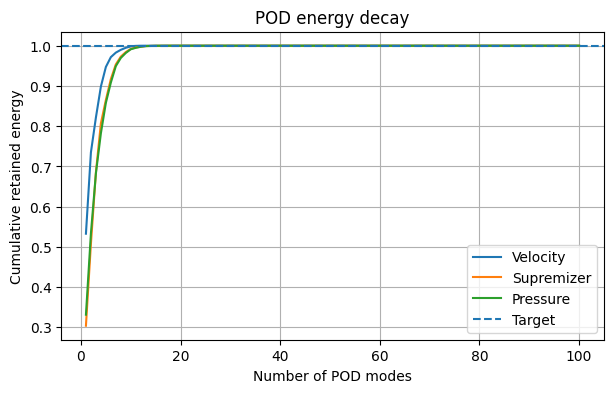

In [32]:
plt.figure(figsize=(7, 4))

plt.plot(
    np.arange(1, len(energy_u) + 1),
    energy_u,
    label="Velocity"
)

plt.plot(
    np.arange(1, len(energy_s) + 1),
    energy_s,
    label="Supremizer"
)

plt.plot(
    np.arange(1, len(energy_p) + 1),
    energy_p,
    label="Pressure"
)

plt.axhline(
    1.0 - POD_TOL,
    linestyle="--",
    label="Target"
)

plt.xlabel("Number of POD modes")
plt.ylabel("Cumulative retained energy")
plt.title("POD energy decay")
plt.grid(True)
plt.legend()
plt.show()


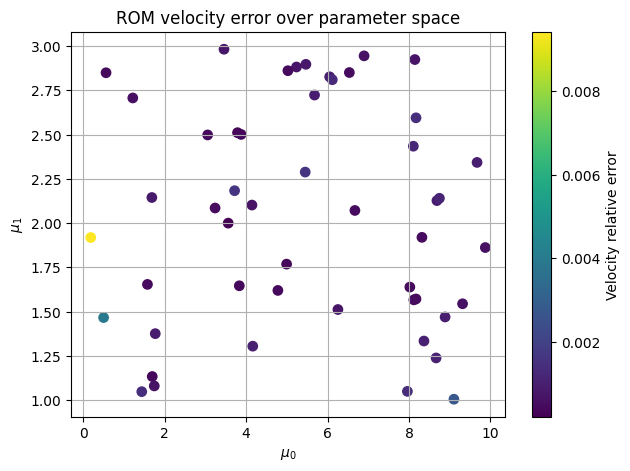

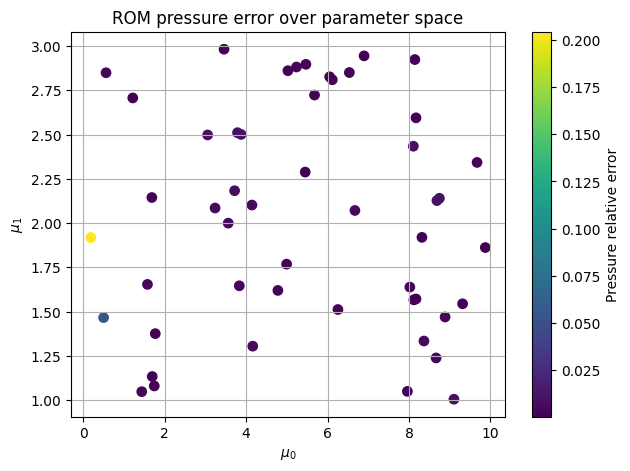

In [38]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    test_parameters[:, 0],
    test_parameters[:, 1],
    c=errors_u,
    s=45
)

plt.colorbar(
    scatter,
    label="Velocity relative error"
)

plt.xlabel(r"$\mu_0$")
plt.ylabel(r"$\mu_1$")
plt.title("ROM velocity error over parameter space")
plt.grid(True)
plt.show()


plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    test_parameters[:, 0],
    test_parameters[:, 1],
    c=errors_p,
    s=45
)

plt.colorbar(
    scatter,
    label="Pressure relative error"
)

plt.xlabel(r"$\mu_0$")
plt.ylabel(r"$\mu_1$")
plt.title("ROM pressure error over parameter space")
plt.grid(True)
plt.show()


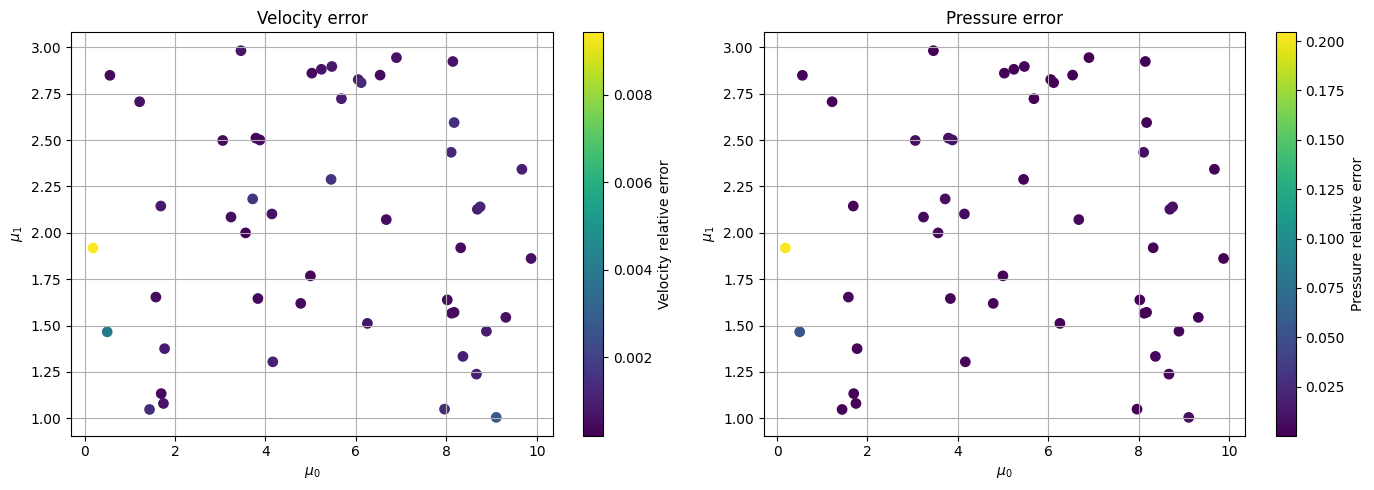

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Velocity error
scatter_u = axes[0].scatter(
    test_parameters[:, 0],
    test_parameters[:, 1],
    c=errors_u,
    s=45
)

fig.colorbar(
    scatter_u,
    ax=axes[0],
    label="Velocity relative error"
)

axes[0].set_xlabel(r"$\mu_0$")
axes[0].set_ylabel(r"$\mu_1$")
axes[0].set_title("Velocity error")
axes[0].grid(True)

# Pressure error
scatter_p = axes[1].scatter(
    test_parameters[:, 0],
    test_parameters[:, 1],
    c=errors_p,
    s=45
)

fig.colorbar(
    scatter_p,
    ax=axes[1],
    label="Pressure relative error"
)

axes[1].set_xlabel(r"$\mu_0$")
axes[1].set_ylabel(r"$\mu_1$")
axes[1].set_title("Pressure error")
axes[1].grid(True)

plt.tight_layout()
plt.show()

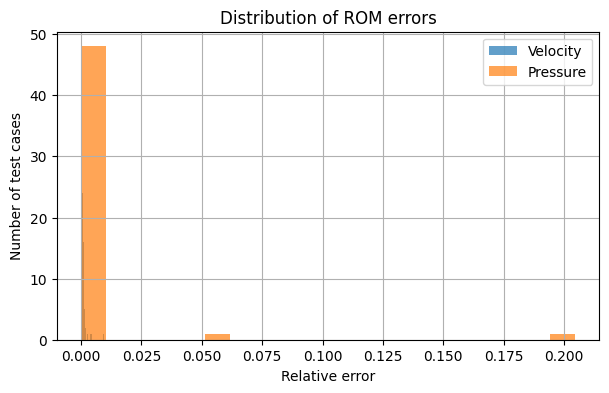

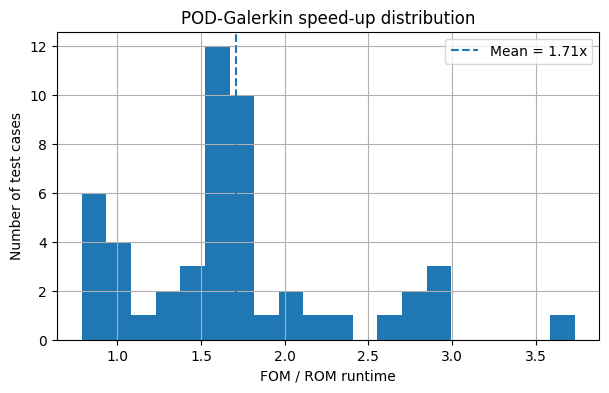

In [34]:
plt.figure(figsize=(7, 4))

plt.hist(
    errors_u,
    bins=20,
    alpha=0.7,
    label="Velocity"
)

plt.hist(
    errors_p,
    bins=20,
    alpha=0.7,
    label="Pressure"
)

plt.xlabel("Relative error")
plt.ylabel("Number of test cases")
plt.title("Distribution of ROM errors")
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(7, 4))

plt.hist(speedup, bins=20)

plt.axvline(
    np.mean(speedup),
    linestyle="--",
    label=f"Mean = {np.mean(speedup):.2f}x"
)

plt.xlabel("FOM / ROM runtime")
plt.ylabel("Number of test cases")
plt.title("POD-Galerkin speed-up distribution")
plt.grid(True)
plt.legend()
plt.show()


## 14. Save the POD-Galerkin model

The saved basis is also useful later for PODNN, so we keep the velocity and pressure POD bases separately as well as the enriched Galerkin basis.

In [35]:
MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "pod_galerkin"
)

os.makedirs(MODEL_DIR, exist_ok=True)

np.savez(
    os.path.join(MODEL_DIR, "pod_galerkin_model.npz"),
    V_u=V_u,
    V_s=V_s,
    V_p=V_p,
    B=B,
    A_r=A_r,
    B_r=B_r,
    energy_u=energy_u,
    energy_s=energy_s,
    energy_p=energy_p,
    eig_u=eig_u,
    eig_s=eig_s,
    eig_p=eig_p,
    N_u=N_u,
    N_s=N_s,
    N_p=N_p,
    N_tot=N_tot,
)

# Sparse matrix used for velocity projections / later diagnostics.
scipy.sparse.save_npz(
    os.path.join(MODEL_DIR, "inner_product_u.npz"),
    inner_product_u
)

print("Saved POD-Galerkin model to:")
print(MODEL_DIR)


Saved POD-Galerkin model to:
/content/drive/MyDrive/ColabNotebooks/MOR-Project/models/pod_galerkin


In [36]:
RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "POD_Galerkin"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

np.savez(
    os.path.join(RESULTS_DIR, "validation.npz"),
    test_parameters=test_parameters,
    errors_u=errors_u,
    errors_p=errors_p,
    times_fom=times_fom,
    times_rom=times_rom,
    speedup=speedup,
    rom_iterations=rom_iterations,
)

print(
    "Saved validation results to:",
    RESULTS_DIR
)


Saved validation results to: /content/drive/MyDrive/ColabNotebooks/MOR-Project/results/POD_Galerkin


In [39]:
M_p_operator = (
    polydim.pde_tools.assembler_utilities.pcc_2_d
    .assemble_mass_operator(
        geometry_utilities,
        mesh,
        mesh_geometric_data,
        pressure_dofs_data,
        pressure_dofs_data,
        pressure_reference_element_data,
        pressure_reference_element_data,
        unit_term
    )
)

M_p = other_ut.make_np_sparse(
    M_p_operator.operator_dofs,
    [pressure_n_dofs, pressure_n_dofs],
    [0, 0]
)

print("M_p shape:", M_p.shape)
print("Expected:", (pressure_n_dofs, pressure_n_dofs))

AttributeError: module 'pypolydim.pypolydim.polydim.pde_tools.assembler_utilities.pcc_2_d' has no attribute 'assemble_mass_operator'

In [ ]:
def relative_pressure_error(reference, approximation, M_p):
    error = reference - approximation

    numerator = np.sqrt(
        error @ (M_p @ error)
    )

    denominator = np.sqrt(
        reference @ (M_p @ reference)
    )

    return numerator / denominator


In [ ]:
errors_p.append(
    relative_pressure_error(
        ref_p,
        pred_p,
        M_p
    )
)